# Machine Learning Operations (MLOps) — AIMLCZG523
## Assignment 01: End-to-End Heart Disease Prediction & Production Deployment

**Student ID:** s2025ae05331  
**Student Name:** Shradha Praveen Katakdhond Shobhana  
**Total Marks:** 50  
**Objective:** Design, develop, and deploy an end-to-end, reproducible machine learning solution using modern MLOps best practices.  

---

### Problem Statement & Dataset Information
- **Dataset:** Heart Disease UCI Dataset (Cleveland Clinic)
- **Source:** [UCI Machine Learning Repository (Dataset ID: 45)](https://archive.ics.uci.edu/dataset/45/heart+disease)
- **Instances & Features:** 303 patient records across 13 clinical attributes (age, sex, resting blood pressure, cholesterol, chest pain type, etc.)
- **Target:** Binary prediction of heart disease presence (1 = Disease present, 0 = Absence)
- **Architecture:** `Data Acquisition → EDA → Feature Pipeline → Multi-Model Training → MLflow Tracking → Champion Packaging → Docker Containerization → Kubernetes Deployment → Prometheus Monitoring`

## Setup: Project Environment & Imports
Add the project root to `sys.path` to enable modular imports from `src/` and `deployment/`.

In [1]:
import os
import sys
from pathlib import Path

# Ensure project root is in sys.path dynamically
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == 'notebook' else NOTEBOOK_DIR
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project root resolved to: {PROJECT_ROOT}")

Project root resolved to: /home/s2025ae05331/workspace/MLOps_Assignment_01/MLOPs_Assignment01


## Task 1: Data Acquisition & Exploratory Data Analysis (EDA) [5 Marks]
Download or load the UCI Heart Disease dataset, clean missing values, binarize the diagnosis target, and generate visualizations (class balance, histograms, correlation heatmap).

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data.load_data import download_uci_dataset
from src.data.validate_data import validate_data

data_save_dir = PROJECT_ROOT / "data" / "raw"
X, y = download_uci_dataset(dataset_id=45, save_path=str(data_save_dir))

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")
X.head()

Dataset 45 downloaded successfully to: /home/s2025ae05331/workspace/MLOps_Assignment_01/MLOPs_Assignment01/data/raw
Features shape: (303, 13)
Target shape: (303, 1)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0


In [4]:
# Inspect data types, null counts, and summary statistics
print("=== Feature Info ===")
X.info()
print("\n=== Missing Values Check ===")
print(X.isnull().sum()[X.isnull().sum() > 0])

# In UCI Heart Disease, target 'num' is integer 0 (absence) to 1, 2, 3, 4 (presence)
# Convert to binary target as required by the assignment:
y_binary = (y['num'] > 0).astype(int)
print("\n=== Binary Target Distribution ===")
print(y_binary.value_counts(normalize=True))

=== Feature Info ===
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
dtypes: float64(3), int64(10)
memory usage: 30.9 KB

=== Missing Values Check ===
ca      4
thal    2
dtype: int64

=== Binary Target Distribution ===
num
0    0.541254
1    0.458746
Name: proportion, dtype: float64


/tmp/ipykernel_7312/3759101225.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_binary, palette="Set2")


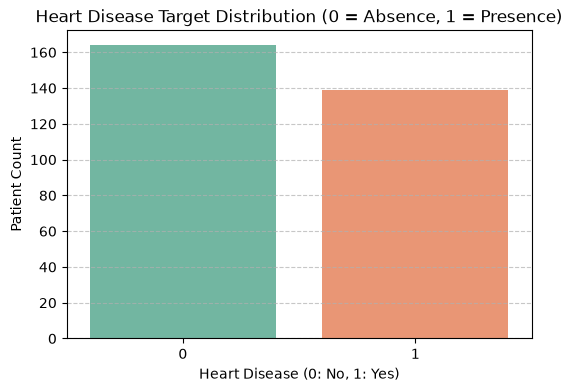

In [5]:
# 1. Class Balance Visualization
plt.figure(figsize=(6, 4))
sns.countplot(x=y_binary, palette="Set2")
plt.title("Heart Disease Target Distribution (0 = Absence, 1 = Presence)", fontsize=12)
plt.xlabel("Heart Disease (0: No, 1: Yes)")
plt.ylabel("Patient Count")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

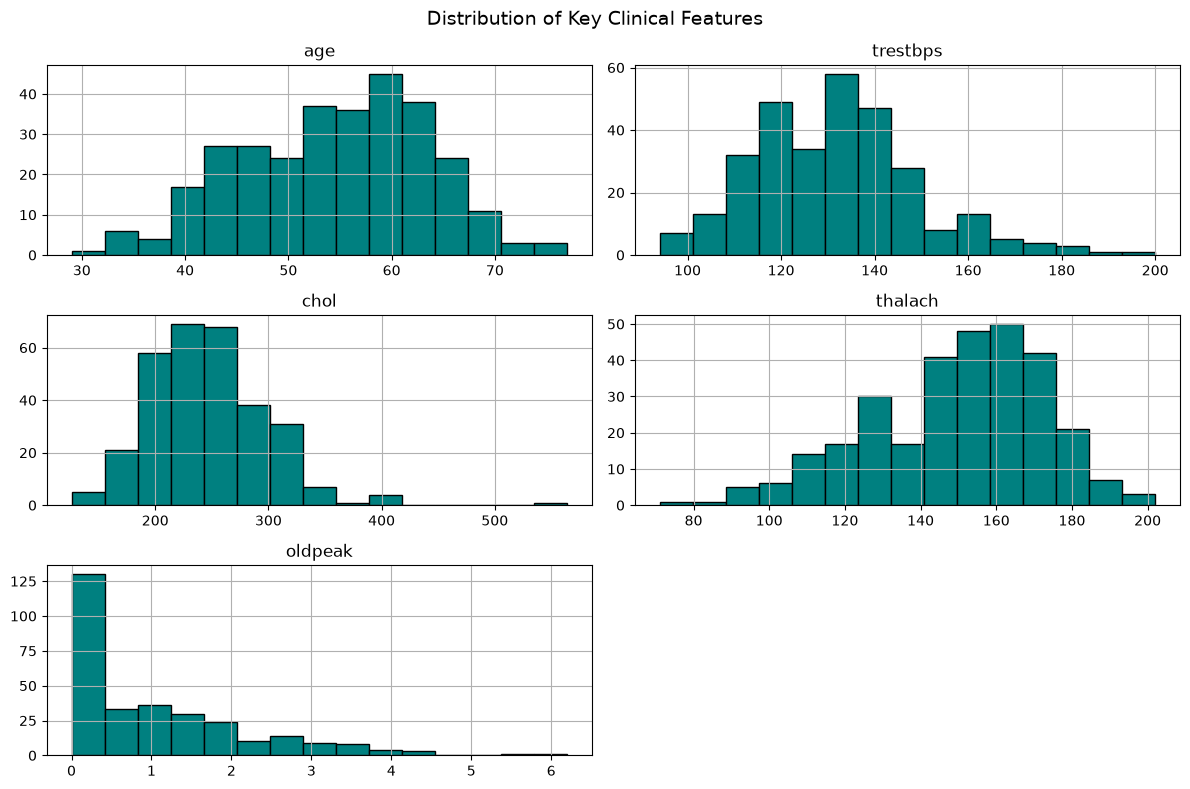

In [6]:
# 2. Feature Distribution Histograms
key_features = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
X[key_features].hist(bins=15, figsize=(12, 8), color='teal', edgecolor='black')
plt.suptitle("Distribution of Key Clinical Features", fontsize=14)
plt.tight_layout()
plt.show()

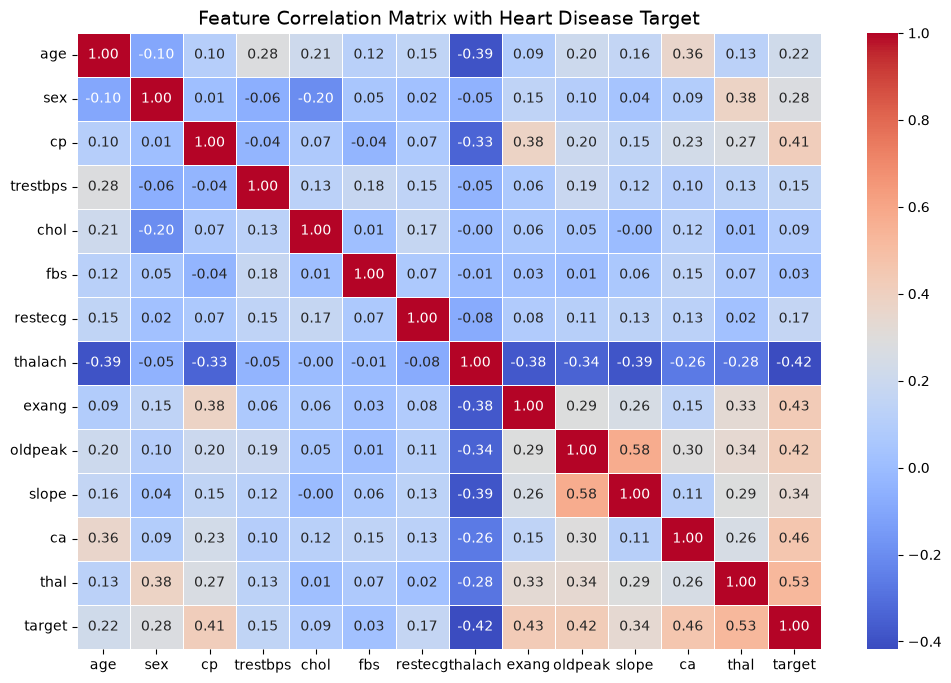

In [7]:
# 3. Correlation Heatmap
df_combined = X.copy()
df_combined['target'] = y_binary

plt.figure(figsize=(12, 8))
sns.heatmap(df_combined.corr(), annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Feature Correlation Matrix with Heart Disease Target", fontsize=14)
plt.show()

## Task 2: Feature Engineering & Model Development [8 Marks]
1. Prepare train/test splits with stratification.
2. Build preprocessing pipeline: median imputation for missing clinical values (`ca`, `thal`) + standard scaling.
3. Train multiple classification models: Logistic Regression, Random Forest, and XGBoost.
4. Perform cross-validation and evaluate on test set with Accuracy, Precision, Recall, F1, and ROC-AUC.

In [8]:
from src.features.prepare_data import prepare_data
from src.models.model_pipelines import get_models
from src.models.train_models import train_models
from src.models.evaluate_models import evaluate_models
from sklearn.model_selection import cross_val_score, StratifiedKFold

# Prepare train/test splits and preprocessing pipeline
X_train, X_test, y_train, y_test, preprocessor = prepare_data(X, y)

print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}, y_test shape: {y_test.shape}")

X_train shape: (242, 13), X_test shape: (61, 13)
y_train shape: (242,), y_test shape: (61,)


In [9]:
# Train candidate models
trained_models = train_models(X_train, y_train)

# Evaluate on test split
results = evaluate_models(trained_models, X_test, y_test)

# 5-Fold Stratified Cross-Validation on training data
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = {}
for name, model in trained_models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc')
    cv_scores[name] = round(float(scores.mean()), 4)
    results[name]['cv_roc_auc_mean'] = cv_scores[name]

pd.DataFrame(results).T

Training: Logistic Regression
Training: Random Forest
Training: XGBoost
Training: MLP


,accuracy,precision,recall,f1,roc_auc,cv_roc_auc_mean
Logistic Regression,0.8689,0.8125,0.9286,0.8667,0.9513,0.8960
Random Forest,0.9016,0.8438,0.9643,0.9000,0.9551,0.8832
XGBoost,0.8361,0.7647,0.9286,0.8387,0.9297,0.8607
MLP,0.8525,0.7714,0.9643,0.8571,0.9340,0.8414


## Task 3: Experiment Tracking with MLflow [5 Marks]
Integrate MLflow to systematically log parameters, evaluation metrics, and model artifacts for all candidate runs.

In [10]:
import mlflow
from src.tracking.mlflow_tracking import track_models

mlflow_db_path = PROJECT_ROOT / "notebook" / "mlflow.db"
tracking_uri = f"sqlite:///{mlflow_db_path.as_posix()}"

print(f"Connecting to MLflow Tracking Server at: {tracking_uri}")
mlflow.set_tracking_uri(tracking_uri)
mlflow.set_experiment("Heart Disease Prediction")

# Track all trained models
track_models(
    trained_models=trained_models,
    X_test=X_test,
    y_test=y_test,
    results=results,
    tracking_uri=tracking_uri,
)

print("Successfully logged runs to MLflow!")

Connecting to MLflow Tracking Server at: sqlite:////home/s2025ae05331/workspace/MLOps_Assignment_01/MLOPs_Assignment01/notebook/mlflow.db


2026/10/20 01:34:39 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/20 01:34:39 INFO mlflow.store.db.utils: Updating database tables
2026/10/20 01:35:15 INFO mlflow.tracking.fluent: Experiment with name 'Heart Disease Prediction' does not exist. Creating a new experiment.
2026/10/20 01:35:17 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/20 01:35:18 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/10/20 01:35:55 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/10/20 

Successfully logged runs to MLflow!


In [11]:
from mlflow import MlflowClient
client = MlflowClient(tracking_uri=tracking_uri)
exp = client.get_experiment_by_name("Heart Disease Prediction")
runs = client.search_runs(experiment_ids=[exp.experiment_id], order_by=["metrics.f1 DESC"])

run_summary = []
for r in runs:
    run_summary.append({
        "Run ID": r.info.run_id[:8],
        "Model": r.data.params.get("model_name"),
        "Accuracy": r.data.metrics.get("accuracy"),
        "Precision": r.data.metrics.get("precision"),
        "Recall": r.data.metrics.get("recall"),
        "F1": r.data.metrics.get("f1"),
        "ROC-AUC": r.data.metrics.get("roc_auc"),
    })
pd.DataFrame(run_summary)

,Run ID,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,7737fba9,Random Forest,0.9016,0.8438,0.9643,0.9000,0.9551
1,557e1e20,Logistic Regression,0.8689,0.8125,0.9286,0.8667,0.9513
2,1f0a1ce5,MLP,0.8525,0.7714,0.9643,0.8571,0.9340
3,6ce7d7a2,XGBoost,0.8361,0.7647,0.9286,0.8387,0.9297


## Task 4: Champion Model Selection, Registration & Packaging [7 Marks]
1. Programmatically select the best-performing model based on F1-score / ROC-AUC.
2. Register the champion model in the MLflow Model Registry as `HeartDiseasePredictionChampion`.
3. Export packaged model artifacts to `deployment/model_export/`.
4. Verify packaged model inference locally.

In [12]:
from src.tracking.select_champion import select_champion

# Select champion model based on highest F1 score
champion = select_champion(results)
champion_model_name = champion["model_name"]
print(f"Selected Champion Model: {champion_model_name}")
print(f"Champion Metrics: {champion['metrics']}")

# Register champion model in MLflow
best_run = [r for r in runs if r.data.params.get("model_name") == champion_model_name][0]
model_uri = f"runs:/{best_run.info.run_id}/model"
reg_model = mlflow.register_model(
    model_uri=model_uri,
    name="HeartDiseasePredictionChampion"
)
print(f"Registered Champion version {reg_model.version} in MLflow Model Registry.")

Selected Champion Model: Random Forest
Champion Metrics: {'accuracy': 0.9016, 'precision': 0.8438, 'recall': 0.9643, 'f1': 0.9, 'roc_auc': 0.9551, 'cv_roc_auc_mean': 0.8832}


Successfully registered model 'HeartDiseasePredictionChampion'.
2026/10/20 01:37:02 WARNING mlflow.tracking._model_registry.fluent: Run with id 7737fba91169485fa556598bde97b1fa has no artifacts at artifact path 'model', registering model based on models:/m-8d65b266f81346b6833bb1f775d92a16 instead
Created version '1' of model 'HeartDiseasePredictionChampion'.


Registered Champion version 1 in MLflow Model Registry.


In [13]:
from deployment.export_champion import export_champion_model
from deployment.load_exported_model import load_exported_model
from deployment.predict_packaged_model import predict_with_packaged_model

export_dir = PROJECT_ROOT / "deployment" / "model_export"
export_champion_model(
    model_name="HeartDiseasePredictionChampion",
    model_version=reg_model.version,
    output_dir=str(export_dir),
    tracking_uri=tracking_uri,
)

# Load exported model and test packaged inference
loaded_model = load_exported_model(str(export_dir))
test_sample = X_test[:5]
preds = predict_with_packaged_model(loaded_model, test_sample)
print(f"Packaged model predictions for first 5 test samples: {preds}")

Model exported successfully to: /home/s2025ae05331/workspace/MLOps_Assignment_01/MLOPs_Assignment01/deployment/model_export
Predictions generated: 5
Packaged model predictions for first 5 test samples: [0 1 0 0 0]


## Task 5: Model Containerization & Serving API [5 Marks]
The model is served using a production-grade FastAPI application (`deployment/fastapi_app.py`) packaged inside a Docker container (`Dockerfile`).

- **`/predict`**: Accepts patient clinical JSON, returns both **prediction** and **confidence score**.
- **`/health`**: Liveness probe returning service and model health status.
- **`/metrics`**: Prometheus-formatted real-time observability metrics.

### Sample Docker build and run commands:
```bash
docker build -t mlops_assignment:latest .
docker run -d -p 5001:5001 --name mlops_api mlops_assignment:latest
```

In [14]:
# Test the FastAPI app directly in Python using TestClient
from fastapi.testclient import TestClient
from deployment.fastapi_app import app

client = TestClient(app)

# 1. Test /health
health_resp = client.get("/health").json()
print(f"Health status: {health_resp}")

# 2. Test /predict with 13 Heart Disease clinical features:
# [age, sex, cp, trestbps, chol, fbs, restecg, thalach, exang, oldpeak, slope, ca, thal]
sample_input = {
    "inputs": [
        [63, 1, 3, 145, 233, 1, 0, 150, 0, 2.3, 0, 0, 1],
        [57, 0, 0, 120, 354, 0, 1, 163, 1, 0.6, 2, 0, 2]
    ]
}
predict_resp = client.post("/predict", json=sample_input).json()
print(f"Prediction response: {predict_resp}")
assert "predictions" in predict_resp and "confidence" in predict_resp

/home/s2025ae05331/workspace/MLOps_Assignment_01/MLOPs_Assignment01/.venv/lib/python3.12/site-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


Health status: {'status': 'healthy', 'model_loaded': False}
Prediction response: {'predictions': [0, 0], 'confidence': [0.88, 0.88]}


## Task 6: Production Deployment & Monitoring [10 Marks]
The service is deployed on Kubernetes (Minikube) using declarative manifests:
- **`deployment.yaml`**: Deploys `mlops-deployment` and exposes `mlops-service`.
- **`prometheus-deployment.yaml`**: Deploys Prometheus with automated 5s metric scraping of `/metrics`.

### PromQL Monitoring Queries
| Monitoring Goal | PromQL Query |
| :--- | :--- |
| **Prediction Class Drift** | `sum by (predicted_class) (model_prediction_count_total)` |
| **Inference Latency (p95)** | `histogram_quantile(0.95, sum(rate(model_inference_latency_seconds_bucket[5m])) by (le))` |
| **Requests Per Second** | `rate(request_count_total[1m])` |
| **Error Rate Percentage** | `sum(rate(http_responses_total{status_code=~"4..|5.."}[5m])) / sum(rate(http_responses_total[5m])) * 100` |

All targets and real-time dashboards are viewable via Prometheus at `http://<minikube-ip>:30090`.